# Data Storytelling & Data Visualization Mastery
## Udemy End of Course Assignment
#### Visualization Workbook by Sebastian Einar Salas Røkholt

[Link to Udemy course](https://ibm-learning.udemy.com/course/mastering-the-art-of-data-visualization-2020/learn/practice/1183600#overview)

---

### Notebook Index
    1 - Introduction & Setup
    2 - Exploratory Data Analysis
    3 - Visualization 1
    4 - Visualization 2

### 1 - Introduction & Setup 

In [23]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

PROJECT_ROOT = os.getcwd()
DATA_PATH = f"{PROJECT_ROOT}/data/Data+File+LightSpeed.xlsx"

In [2]:
df = pd.read_excel(DATA_PATH)
df.head(20)

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,Month,Cinema,tickets,NaN,Month,Cinema,Product,Sales Number,Sales Rev
4,NaN,2019-02-01 00:00:00,1,27034,NaN,2019-02-01 00:00:00,1,Popcorn,18342,82539
5,NaN,2019-03-01 00:00:00,1,29301,NaN,2019-02-01 00:00:00,1,Soda,17340,48552
6,NaN,2019-04-01 00:00:00,1,31269,NaN,2019-02-01 00:00:00,1,Candy,4245,11037
7,NaN,2019-02-01 00:00:00,2,22775,NaN,2019-03-01 00:00:00,1,Popcorn,19304,86868
8,NaN,2019-03-01 00:00:00,2,21465,NaN,2019-03-01 00:00:00,1,Soda,16790,47012
9,NaN,2019-04-01 00:00:00,2,24138,NaN,2019-03-01 00:00:00,1,Candy,3784,9838.4


The spreadsheet contains multiple tables, so I'll extract each table to a separate Pandas DataFrame.

In [3]:
# Tickets table starts at row 4 with header "Month, Cinema, tickets", 9 rows excluding headers
tickets_df = pd.read_excel(DATA_PATH, header=4, usecols="B:D", nrows=10)
tickets_df = tickets_df.dropna().reset_index(drop=True)
tickets_df["Month"] = pd.to_datetime(tickets_df["Month"]).dt.strftime("%Y %b")
tickets_df.head(10)


,Month,Cinema,tickets
0,2019 Feb,1.0,27034.0
1,2019 Mar,1.0,29301.0
2,2019 Apr,1.0,31269.0
3,2019 Feb,2.0,22775.0
4,2019 Mar,2.0,21465.0
5,2019 Apr,2.0,24138.0
6,2019 Feb,3.0,42546.0
7,2019 Mar,3.0,39490.0
8,2019 Apr,3.0,38093.0


In [4]:
# Product costs  table starts at row 15: "Cinema, Product, Cost"
product_df = pd.read_excel(DATA_PATH, header=15, usecols="B:D", nrows=10)
product_df = product_df.dropna().reset_index(drop=True)
product_df.head(10)

,Cinema,Product,Cost
0,1.0,Popcorn,4.50
1,1.0,Soda,2.80
2,1.0,Candy,2.60
3,2.0,Popcorn,4.20
4,2.0,Soda,3.50
5,2.0,Candy,2.85
6,3.0,Popcorn,4.00
7,3.0,Soda,3.15
8,3.0,Candy,2.49


In [5]:
# Extract the product sales table: rows 4-31 and columns F-J.
sales_df = pd.read_excel(DATA_PATH, header=4, usecols="F:J", nrows=27)
sales_df = sales_df.dropna().reset_index(drop=True)
sales_df = sales_df.rename(columns={"Month.1": "Month", "Cinema.1": "Cinema", "Sales Rev": "Sales Revenue"})
sales_df["Month"] = pd.to_datetime(sales_df["Month"]).dt.strftime("%Y %b")
sales_df.head(27)

,Month,Cinema,Product,Sales Number,Sales Revenue
0,2019 Feb,1,Popcorn,18342,82539.00
1,2019 Feb,1,Soda,17340,48552.00
2,2019 Feb,1,Candy,4245,11037.00
3,2019 Mar,1,Popcorn,19304,86868.00
4,2019 Mar,1,Soda,16790,47012.00
5,2019 Mar,1,Candy,3784,9838.40
6,2019 Apr,1,Popcorn,17422,78399.00
7,2019 Apr,1,Soda,15308,42862.40
8,2019 Apr,1,Candy,5688,14788.80
9,2019 Feb,2,Popcorn,19981,83920.20


## Exploratory Data Analysis

In [6]:
# Print some summary statistics
dfs = [tickets_df, product_df, sales_df]
for df in dfs:
    display(df.describe())

,Cinema,tickets
count,9.000000,9.000000
mean,2.000000,30679.000000
std,0.866025,7738.826688
min,1.000000,21465.000000
25%,1.000000,24138.000000
50%,2.000000,29301.000000
75%,3.000000,38093.000000
max,3.000000,42546.000000


,Cinema,Cost
count,9.000000,9.000000
mean,2.000000,3.343333
std,0.866025,0.740287
min,1.000000,2.490000
25%,1.000000,2.800000
50%,2.000000,3.150000
75%,3.000000,4.000000
max,3.000000,4.500000


,Cinema,Sales Number,Sales Revenue
count,27.00000,27.000000,27.000000
mean,2.00000,15316.333333,54606.484074
std,0.83205,7315.430814,31832.769934
min,1.00000,3784.000000,9838.400000
25%,1.00000,8106.500000,20185.185000
50%,2.00000,17330.000000,59055.500000
75%,3.00000,19642.500000,78952.500000
max,3.00000,26711.000000,106844.000000


In [ ]:
# Group total revenue per cinema per month
monthly_cinema_rev = (
    sales_df.groupby(["Month", "Cinema"], as_index=False)["Sales Revenue"]
    .sum()
)

monthly_cinema_rev["Month"] = pd.to_datetime(monthly_cinema_rev["Month"])
monthly_cinema_rev = monthly_cinema_rev.sort_values("Month")
monthly_cinema_rev["Month"] = monthly_cinema_rev["Month"].dt.strftime("%Y %b")

monthly_cinema_rev

/tmp/ipykernel_293746/1930456806.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  monthly_cinema_rev["Month"] = pd.to_datetime(monthly_cinema_rev["Month"])


,Month,Cinema,Sales Revenue
3,2019 Feb,1,142128.00
4,2019 Feb,2,160729.00
5,2019 Feb,3,193261.51
6,2019 Mar,1,143718.40
7,2019 Mar,2,149299.10
8,2019 Mar,3,204142.10
0,2019 Apr,1,136050.20
1,2019 Apr,2,152514.10
2,2019 Apr,3,192532.66


In [ ]:
# Calculates the total number of tickets sold per cinema over the three month period
tickets_per_cinema = tickets_df.groupby("Cinema", as_index=False)["tickets"].sum().rename(columns={"tickets": "Total Ticket Sales"})
tickets_per_cinema

# Calculates the total revenue per cinema
revenue_per_cinema = sales_df.groupby("Cinema", as_index=False)["Sales Revenue"].sum()
revenue_per_cinema = revenue_per_cinema.rename(columns={"Sales Revenue": "Total Revenue"})

# Calculate avg cost/price per cinema
avg_cost_per_cinema = product_df.groupby("Cinema", as_index=False)["Cost"].mean()
avg_cost_per_cinema = avg_cost_per_cinema.rename(columns={"Cost": "Avg Product Price"})

# Calculate the total product sold per cinema
product_per_cinema = sales_df.groupby("Cinema", as_index=False)["Sales Number"].sum()
product_per_cinema = product_per_cinema.rename(columns={"Sales Number": "Total Product Sales"})

# Merge aggregate metrics to one DataFrame
cinema_metrics = tickets_per_cinema.merge(revenue_per_cinema, on="Cinema", how="outer")
cinema_metrics = cinema_metrics.merge(avg_cost_per_cinema, on="Cinema", how="outer")
cinema_metrics = cinema_metrics.merge(product_per_cinema, on="Cinema", how="outer")
cinema_metrics["Cinema"] = cinema_metrics["Cinema"].astype(int)

# Calculate product volume & revenue per ticket sold (concession stand products sold + revenue per moviegoer)
cinema_metrics["Product Sales per Ticket"] = cinema_metrics["Total Product Sales"] / cinema_metrics["Total Ticket Sales"]
cinema_metrics["Revenue per Ticket"] = cinema_metrics["Total Revenue"] / cinema_metrics["Total Ticket Sales"]

cinema_metrics

,Cinema,Total Ticket Sales,Total Revenue,Avg Product Price,Total Product Sales,Product Sales per Ticket,Revenue per Ticket
0,1,87604.0,421896.60,3.300000,118223,1.349516,4.815951
1,2,68378.0,462542.20,3.516667,123760,1.809939,6.764489
2,3,120129.0,589936.27,3.213333,171558,1.428115,4.910856


## Visualisations

### Visualisation 1: Total Revenue per Cinema per Month

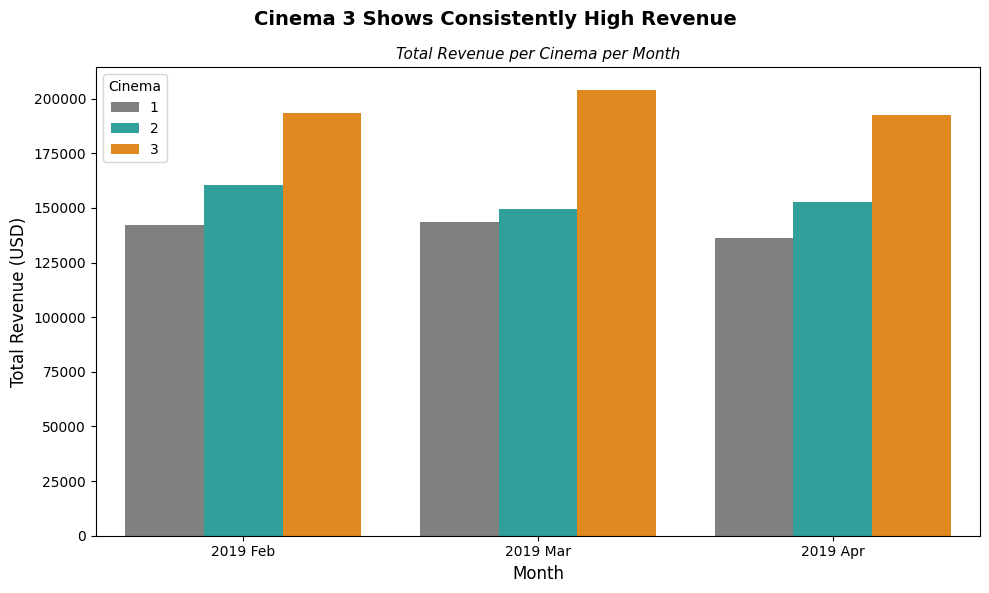

In [63]:
# Plot
fig, ax = plt.subplots(figsize=(10,6))
colors = palette = {
    1: "grey",
    2: "lightseagreen",
    3: "darkorange"
}
sns.barplot(data=monthly_cinema_rev, x="Month", y="Sales Revenue", hue="Cinema", palette=colors, ax=ax)

fig.suptitle("Cinema 3 Shows Consistently High Revenue", fontsize=14, weight="bold")
ax.set_title("Total Revenue per Cinema per Month", fontsize=11, style="italic")
ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Total Revenue (USD)", fontsize=12)
ax.legend(title="Cinema")
plt.tight_layout()
plt.show()


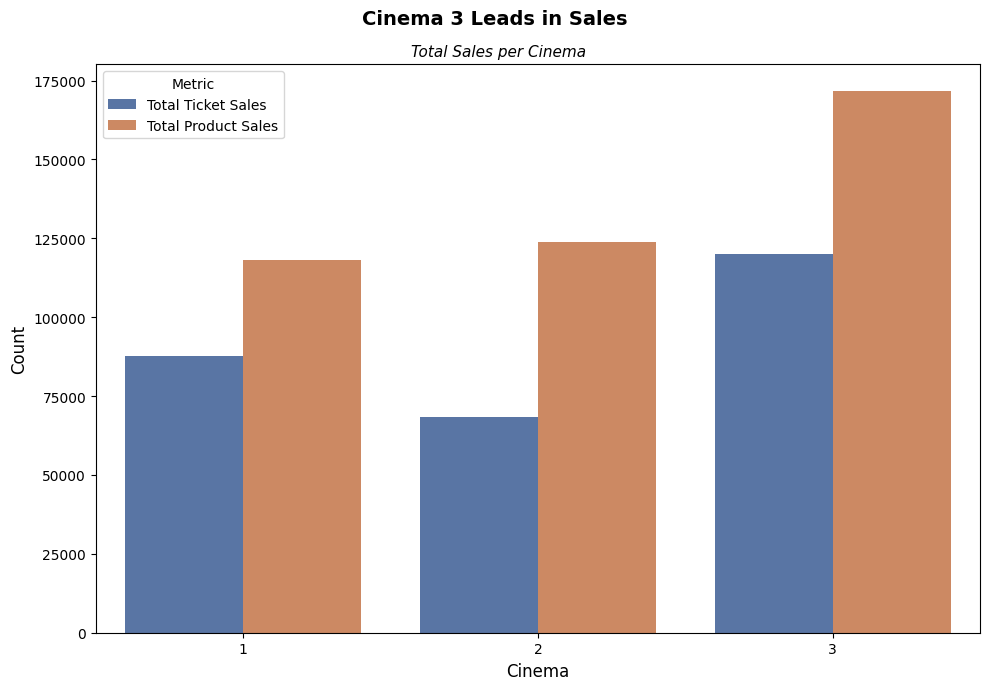

In [ ]:
# Reshape into long format for seaborn
melt_df = cinema_metrics.melt(
    id_vars="Cinema",
    value_vars=["Total Ticket Sales", "Total Product Sales"],
    var_name="Metric",
    value_name="Count"
)

plt.figure(figsize=(10,7))
sns.barplot(
    data=melt_df,
    x="Cinema",
    y="Count",
    hue="Metric",
    palette="deep"
)

plt.suptitle("Cinema 3 Leads in Sales", fontsize=14, weight="bold")
plt.title("Total Sales per Cinema                ", fontsize=11, style="italic")
plt.xlabel("Cinema", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()


### Visualization 2:  Total Sales per Cinema

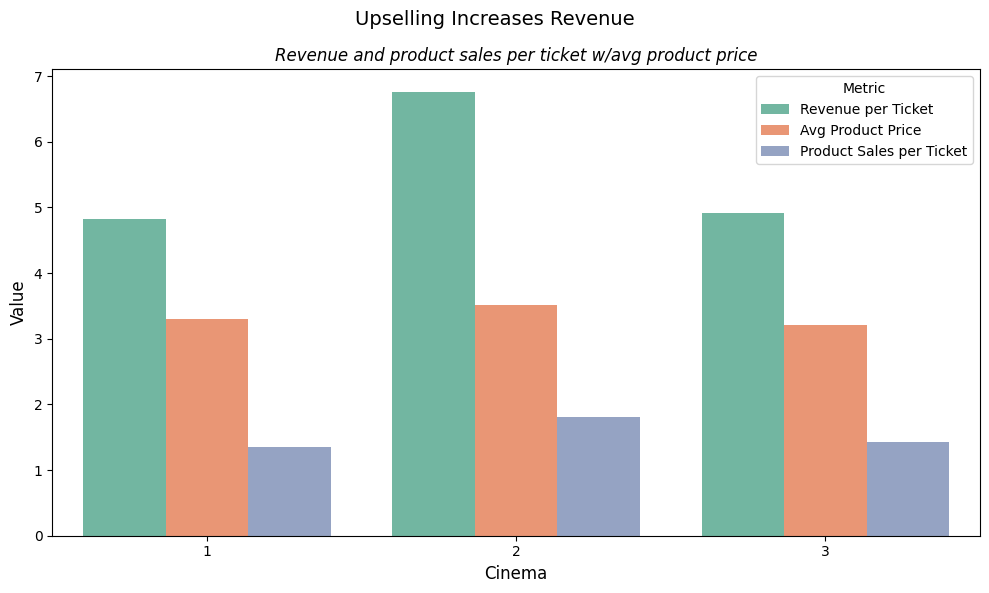

In [ ]:
plot_df = cinema_metrics.copy()
plot_df["Cinema"] = plot_df["Cinema"].astype(str) 

# Melt to long format for seaborn
plot_long = cinema_metrics.melt(
    id_vars="Cinema",
    value_vars=["Revenue per Ticket", "Avg Product Price", "Product Sales per Ticket"],
    var_name="Metric",
    value_name="Value"
)

fig, ax = plt.subplots(figsize=(10,6))
sns.barplot(data=plot_long, x="Cinema", y="Value", hue="Metric", palette="Set2", errorbar=None, ax=ax
)

fig.suptitle("Upselling Increases Revenue", fontsize=14)
ax.set_title("Revenue and product sales per ticket w/avg product price", fontsize=12, style="italic")
ax.set_xlabel("Cinema", fontsize=12)
ax.set_ylabel("Value", fontsize=12)
ax.legend(title="Metric")
plt.tight_layout()
plt.show()


Cinema 2 sells more product per ticket, despite higher prices

/tmp/ipykernel_293746/3071536231.py:17: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  last_month = pd.to_datetime(cinema3_hist["Month"]).max()
/tmp/ipykernel_293746/3071536231.py:30: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cinema3_all["Month"] = pd.to_datetime(cinema3_all["Month"])


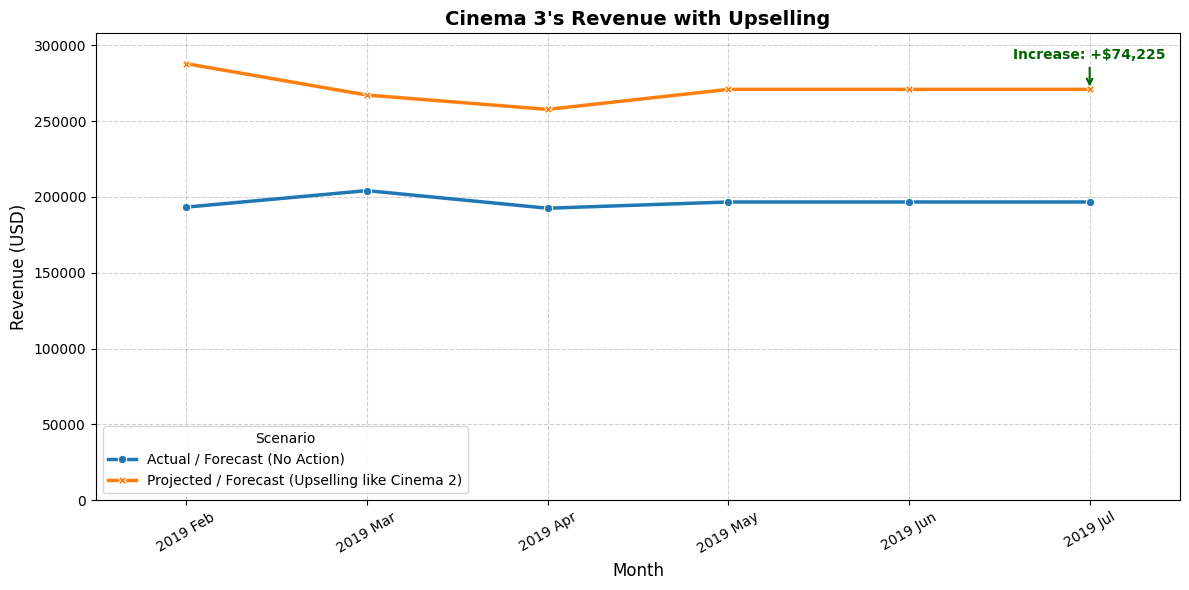

In [83]:

# Benchmark revenue per ticket for Cinema 2
cinema2_rev_per_ticket = cinema_metrics.loc[cinema_metrics["Cinema"] == 2, "Revenue per Ticket"].values[0]

# Cinema 3 historical data
cinema3_hist = (sales_df[sales_df["Cinema"] == 3].groupby("Month", as_index=False)["Sales Revenue"].sum().rename(columns={"Sales Revenue": "total_revenue"}))
tickets_c3 = tickets_df[tickets_df["Cinema"] == 3][["Month", "tickets"]].rename(columns={"tickets":"tickets_sold"})
cinema3_hist = cinema3_hist.merge(tickets_c3, on="Month", how="left")

# Project historical revenue if upselling like Cinema 2
cinema3_hist["projected_revenue"] = cinema3_hist["tickets_sold"] * cinema2_rev_per_ticket

# Forecast for next 3 months. Calculates the average ticket sales and average revenues
avg_tickets = cinema3_hist["tickets_sold"].mean()
avg_actual_rev = cinema3_hist["total_revenue"].mean()

# Generate future months after last observed month
last_month = pd.to_datetime(cinema3_hist["Month"]).max()
future_months = pd.date_range(start=last_month + pd.offsets.MonthBegin(1), periods=3, freq="MS")

# Builds the forecast DataFrame
forecast = pd.DataFrame({
    "Month": future_months,
    "tickets_sold": avg_tickets,
})
forecast["total_revenue"] = avg_actual_rev    # Scenario 1: no action taken
forecast["projected_revenue"] = forecast["tickets_sold"] * cinema2_rev_per_ticket  # Scenario 2: Upselling like Cinema 2

# Add forecast to cinema 3 dataframe
cinema3_all = pd.concat([cinema3_hist, forecast], ignore_index=True)
cinema3_all["Month"] = pd.to_datetime(cinema3_all["Month"])
cinema3_all = cinema3_all.sort_values("Month")
cinema3_all["Month_str"] = cinema3_all["Month"].dt.strftime("%Y %b")

# Melt for plotting
plot_df = cinema3_all.melt(
    id_vars=["Month_str", "Month"],
    value_vars=["total_revenue", "projected_revenue"],
    var_name="Scenario",
    value_name="Revenue"
)

plot_df["Scenario"] = plot_df["Scenario"].map({
    "total_revenue": "Actual / Forecast (No Action)",
    "projected_revenue": "Projected / Forecast (Upselling like Cinema 2)"
})

# Plotting
plt.figure(figsize=(12,6))
sns.lineplot(
    data=plot_df,
    x="Month_str",
    y="Revenue",
    hue="Scenario",
    style="Scenario",
    markers=True,
    dashes=False,
    linewidth=2.5
)

# Annotating the difference in revenue for July
july_row = plot_df[(plot_df["Month_str"] == "2019 Jul")]
july_actual = july_row.loc[july_row["Scenario"] == "Actual / Forecast (No Action)", "Revenue"].values[0]
july_proj   = july_row.loc[july_row["Scenario"] == "Projected / Forecast (Upselling like Cinema 2)", "Revenue"].values[0]
increase = july_proj - july_actual

plt.annotate(
    f"Increase: +${increase:,.0f}",
    xy=("2019 Jul", july_proj), 
    xytext=("2019 Jul", july_proj + 20000),
    ha="center", fontsize=10, weight="bold", color="darkgreen",
    arrowprops=dict(arrowstyle="->", color="darkgreen", lw=1.5)
)

plt.title("Cinema 3's Revenue with Upselling", fontsize=14, weight="bold")
plt.xlabel("Month", fontsize=12)
plt.ylabel("Revenue (USD)", fontsize=12)
plt.ylim(0, plot_df["Revenue"].max()+20000)
plt.xticks(rotation=30)
plt.margins(x=0.1)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(title="Scenario")
plt.tight_layout()
plt.show()
